Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_3 (Flatten)             │ (None, 862)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │       110,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 119,110 (465.27 KB)

 Trainable params: 119,110 (465.27 KB)

 Non-trainable params: 0 (0.00 B)

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
[0]	validation_0-mlogloss:1.68576
[1]	validation_0-mlogloss:1.59387
[2]	validation_0-mlogloss:1.51382
[3]	validation_0-mlogloss:1.44185
[4]	validation_0-mlogloss:1.37706
[5]	validation_0-mlogloss:1.31899
[6]	validation_0-mlogloss:1.26700
[7]	validation_0-mlogloss:1.21838
[8]	validation_0-mlogloss:1.17382
[9]	validation_0-mlogloss:1.13285
[10]	validation_0-mlogloss:1.09662
[11]	validation_0-mlogloss:1.06131
[12]	validation_0-mlogloss:1.02816
[13]	validation_0-mlogloss:0.99921
[14]	validation_0-mlogloss:0.97191
[15]	validation_0-mlogloss:0.94480
[16]	validation_0-mlogloss:0.91907
[17]	validation_0-mlogloss:0.89576
[18]	validation_0-mlogloss:0.87358
[19]	validation_0-mlogloss:0.85363
[20]	validation_0-mlogloss:0.83389
[21]	validation_0-mlogloss:0.81563
[22]	validation_0-mlogloss:0.79991
[23]	validation_0-mlogloss:0.78413
[24]	validation_0-mlogloss:0.77007
[25]	validation_0-mlogloss:0.75594
[26]	validation_0-mlog

C:\Users\Lenovo\anaconda3\Lib\site-packages\xgboost\sklearn.py:889: UserWarning: `early_stopping_rounds` in `fit` method is deprecated for better compatibility with scikit-learn, use `early_stopping_rounds` in constructor or`set_params` instead.
  warnings.warn(


[29]	validation_0-mlogloss:0.70869
[30]	validation_0-mlogloss:0.69928
[31]	validation_0-mlogloss:0.68967
[32]	validation_0-mlogloss:0.68148
[33]	validation_0-mlogloss:0.67348
[34]	validation_0-mlogloss:0.66680
[35]	validation_0-mlogloss:0.65975
[36]	validation_0-mlogloss:0.65349
[37]	validation_0-mlogloss:0.64679
[38]	validation_0-mlogloss:0.63991
[39]	validation_0-mlogloss:0.63403
[40]	validation_0-mlogloss:0.62920
[41]	validation_0-mlogloss:0.62457
[42]	validation_0-mlogloss:0.62004
[43]	validation_0-mlogloss:0.61533
[44]	validation_0-mlogloss:0.61165
[45]	validation_0-mlogloss:0.60780
[46]	validation_0-mlogloss:0.60459
[47]	validation_0-mlogloss:0.60184
[48]	validation_0-mlogloss:0.59926
[49]	validation_0-mlogloss:0.59743
[50]	validation_0-mlogloss:0.59487
[51]	validation_0-mlogloss:0.59248
[52]	validation_0-mlogloss:0.59025
[53]	validation_0-mlogloss:0.58775
[54]	validation_0-mlogloss:0.58611
[55]	validation_0-mlogloss:0.58482
[56]	validation_0-mlogloss:0.58241
[57]	validation_0-ml

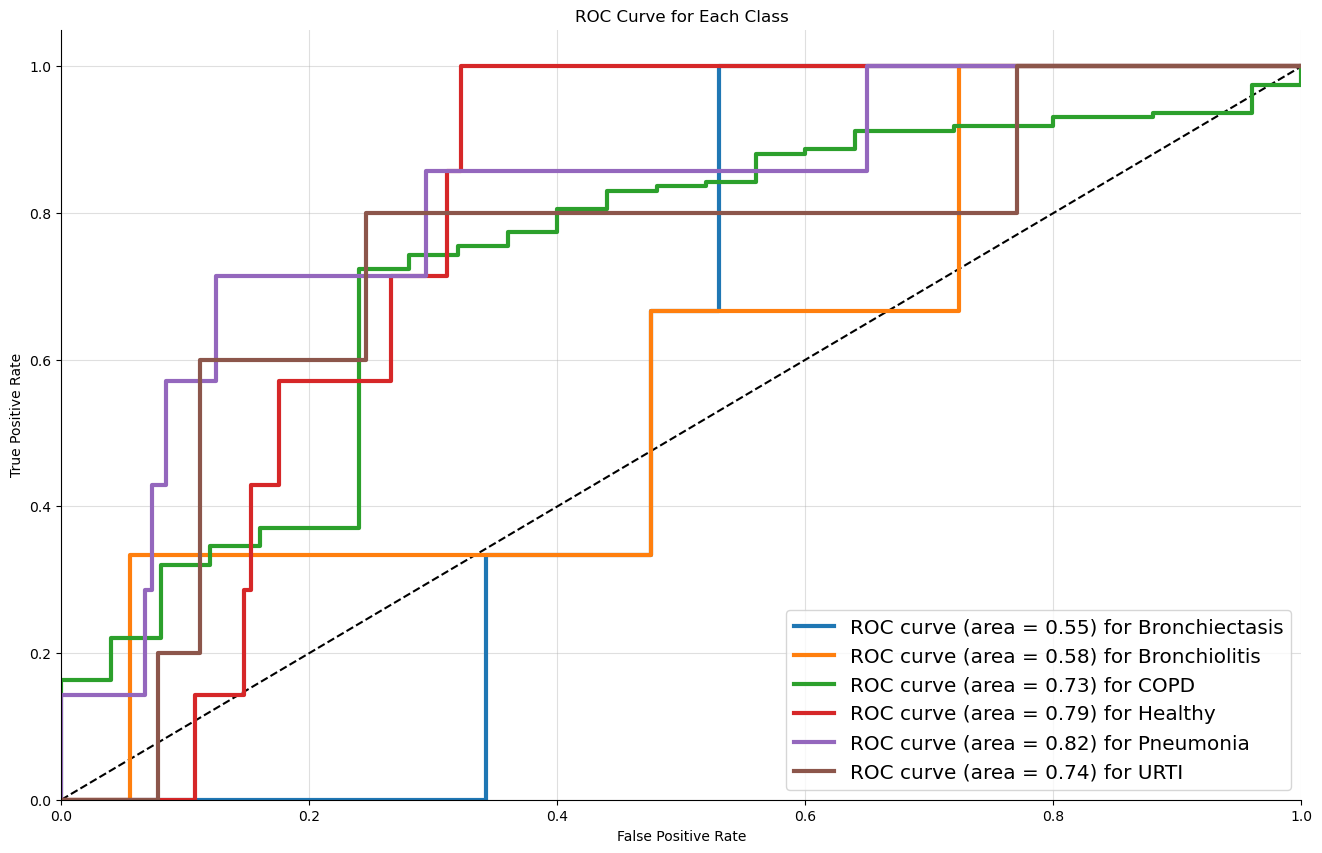

In [9]:
import xgboost as xgb
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import numpy as np
###
from datetime import datetime
from os import listdir
from os.path import isfile, join
import librosa
import numpy as np
import pandas as pd
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Conv2D, MaxPooling2D, GlobalAveragePooling2D, Input, Flatten
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import ModelCheckpoint
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import xgboost as xgb
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

# File paths and loading data
mypath = "E:\\FFF\\respiratory-sound-database\\Respiratory_Sound_Database\\Respiratory_Sound_Database\\audio_and_txt_files\\"
filenames = [f for f in listdir(mypath) if (isfile(join(mypath, f)) and f.endswith('.wav'))]
p_id_in_file = [int(name[:3]) for name in filenames]
p_id_in_file = np.array(p_id_in_file)
max_pad_len = 862

# Feature extraction function using Zero-Crossing Rate
def extract_features(file_name):
    try:
        audio, sample_rate = librosa.load(file_name, res_type='kaiser_fast', duration=20)
        zcr = librosa.feature.zero_crossing_rate(y=audio)
        zcr = np.squeeze(zcr)
        pad_width = max_pad_len - len(zcr)
        zcr = np.pad(zcr, pad_width=(0, pad_width), mode='constant')
    except Exception as e:
        print(f"Error encountered while parsing file: {file_name}")
        print(f"Exception: {e}")
        return None 
    return zcr

filepaths = [join(mypath, f) for f in filenames]
p_diag = pd.read_csv("E:\\FFF\\respiratory-sound-database\\Respiratory_Sound_Database\\Respiratory_Sound_Database/patient_diagnosis.csv", header=None)
labels = np.array([p_diag[p_diag[0] == x][1].values[0] for x in p_id_in_file])
features = [extract_features(file_name) for file_name in filepaths]
features = np.array(features)

# Removing specific labels and converting labels
features1 = np.delete(features, np.where((labels == 'Asthma') | (labels == 'LRTI'))[0], axis=0)
labels1 = np.delete(labels, np.where((labels == 'Asthma') | (labels == 'LRTI'))[0], axis=0)

# One-hot encode labels
le = LabelEncoder()
i_labels = le.fit_transform(labels1)
oh_labels = to_categorical(i_labels)

# Train-test split
x_train, x_test, y_train, y_test = train_test_split(features1, oh_labels, stratify=oh_labels, test_size=0.2, random_state=42)

# Define CNN model for feature extraction
cnn_model = Sequential()
cnn_model.add(Input(shape=(max_pad_len, 1)))
cnn_model.add(Flatten())
cnn_model.add(Dense(128, activation='relu'))
cnn_model.add(Dropout(0.2))
cnn_model.add(Dense(64, activation='relu'))
cnn_model.add(Dropout(0.2))
cnn_model.add(Dense(len(le.classes_), activation='softmax'))

cnn_model.compile(loss='categorical_crossentropy', metrics=['accuracy'], optimizer='adam')
cnn_model.summary()

# Extract features using CNN
x_train_features = cnn_model.predict(x_train)
x_test_features = cnn_model.predict(x_test)

# Train the XGBoost model
xgb_model = xgb.XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.05, subsample=0.9, colsample_bytree=0.8, gamma=0.1, use_label_encoder=False, eval_metric='mlogloss')
xgb_model.fit(x_train_features, np.argmax(y_train, axis=1), early_stopping_rounds=10, eval_set=[(x_test_features, np.argmax(y_test, axis=1))], verbose=True)

# Evaluate model
y_pred = xgb_model.predict(x_test_features)
accuracy = accuracy_score(np.argmax(y_test, axis=1), y_pred)
print(f"XGBoost Test Accuracy: {accuracy:.4f}")

# Evaluating the model on the training set
y_train_pred = xgb_model.predict(x_train_features)
train_accuracy = accuracy_score(np.argmax(y_train, axis=1), y_train_pred)
print(f"XGBoost Training Accuracy: {train_accuracy:.4f}")

# Evaluating the model on the testing set
y_test_pred = xgb_model.predict(x_test_features)
test_accuracy = accuracy_score(np.argmax(y_test, axis=1), y_test_pred)
print(f"XGBoost Testing Accuracy: {test_accuracy:.4f}")

###############################
#$$$$$$$$$$$$$$$$$$$$
# Confusion matrix and classification report
print("Classification Report:")
print(classification_report(np.argmax(y_test, axis=1), y_pred, target_names=le.classes_, zero_division=1))
print("Confusion Matrix:")
print(confusion_matrix(np.argmax(y_test, axis=1), y_pred))

# Plot ROC curves
fpr = dict()
tpr = dict()
roc_auc = dict()
y_test_onehot = to_categorical(np.argmax(y_test, axis=1), num_classes=len(le.classes_))
y_pred_proba = xgb_model.predict_proba(x_test_features)
for i in range(len(le.classes_)):
    fpr[i], tpr[i], _ = roc_curve(y_test_onehot[:, i], y_pred_proba[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# ROC Curve Plot
fig, ax = plt.subplots(figsize=(16, 10))
ax.plot([0, 1], [0, 1], 'k--')
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve for Each Class')
for i in range(len(le.classes_)):
    ax.plot(fpr[i], tpr[i], linewidth=3, label='ROC curve (area = %0.2f) for %s' % (roc_auc[i], le.classes_[i]))
ax.legend(loc="best", fontsize='x-large')
ax.grid(alpha=.4)
sns.despine()
plt.show()
